### 加载数据

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skfolio import Population,MultiPeriodPortfolio
from skfolio import RiskMeasure, PerfMeasure, RatioMeasure
from skfolio.datasets import load_sp500_dataset
from skfolio.preprocessing import prices_to_returns
from ml4t.data.providers.qmt_provider import QmtProvider
from sklearn import set_config
from log_result import init_logger, log_result, log_print
from synthetic_returns import estimate_marginal_stats, synthesize_returns
set_config(transform_output="pandas")
init_logger("CSCV_OOS")      # 只调用一次, 绑定文件名
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 关键: 负号才不会变方块

[log] 已绑定: D:\machine-learning-for-trading\case_studies\lazy_trading\logs\CSCV_OOS.log


In [2]:
# 加载数据
prices = pl.read_parquet("hs_funds_prices.parquet").to_pandas()
prices = prices.set_index('timestamp')
prices = prices.ffill()
prices = prices[prices.index.year > 2022]
#prices = prices[prices.index.year < 2017]
all_symbols = prices.columns
log_print(f"资产池: {len(all_symbols)} 只 | {len(prices)} 天 | {prices.index[0].date()} ~ {prices.index[-1].date()}",section="资产池", echo=True)

# 市场基准（从资产池中取出）
bench_symbols = ["510880.SH","510300.SH"]
benchs = [prices[bench_symbol] for bench_symbol in bench_symbols]
#prices = prices.drop(columns=bench_symbols)

# 双口径收益率: X=绝对收益, X_net=超额收益(减基准), 筛选与训练统一用X_net
X = prices_to_returns(prices, drop_inceptions_nan=False)
bench_rets = [prices_to_returns(bench.to_frame("bench"), drop_inceptions_nan=False)["bench"] for bench in benchs]
X_net = X.sub(bench_rets[1], axis=0)

# Inf 检查（两口径分别报告）
for label, df in [("X", X), ("X_net", X_net)]:
    inf = df.columns[np.isinf(df).any(axis=0)]
    print(f"{label} Inf列 {len(inf)}" + (f" -> {inf.tolist()}" if len(inf) else ""))

# 异常收益检查: 以超额口径判定, 同步剔除, 保证两口径列集一致
bad = X_net.columns[(X_net.abs() > 0.25).any()]
X = X.drop(columns=bad)
X_net = X_net.drop(columns=bad)
msg = f"异常剔除(±25%): {len(bad)} 列 -> {bad.tolist()}" if len(bad) else "异常剔除(±25%): 0 列"
print(msg)
print(f"清洗后: {X.shape[0]} 天 x {X.shape[1]} 资产 | 列集一致: {list(X.columns) == list(X_net.columns)}")

资产池: 2141 只 | 901 天 | 2023-01-03 ~ 2026-09-18
X Inf列 0
X_net Inf列 0
异常剔除(±25%): 1 列 -> ['511580.SH']
清洗后: 900 天 x 2140 资产 | 列集一致: True


In [3]:
#stats  = estimate_marginal_stats(X)                        # ① 逐标的统计属性 + 拟合参数表
#X_fake = synthesize_returns(X, random_state=42)            # ② 默认 student_t + 保留截面相关
#X_fake, report = synthesize_returns(X, random_state=42, return_report=True)
X_ctrl = synthesize_returns(X, distribution="gaussian")    # 高斯对照项
X_fake = synthesize_returns(X, random_state=42)

硬截断告警：1 列截断比例超过阈值（最高 159098.SZ: 截断 20.00% / 阈值 23.08% / 样本 25）
硬截断告警：6 列截断比例超过阈值（最高 512420.SH: 截断 16.67% / 阈值 19.35% / 样本 30）


In [3]:
from cpcv_search_base import build_pipeline_src
from cpcv_analysis import plot_oos_vs_bench
from sl_simulation import load_sl_config, simulate_sl, summarize_sl, simulate_fixed, simulate_wf

### Fixed Simulate

In [4]:
from skfolio import Population

### TopK best parameters

In [17]:
topk_params = [{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
]

In [4]:
topk_params = [{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.4, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.4, 'nondomin__fitness_measures': 'sharpe-avgdd-kurt', 'train_size': 252}]

In [9]:
#10~21
topk_params = [{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.5, 'extremes__k': 0.2, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 25, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}]

In [16]:
topk_params = [{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 25, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}]

In [26]:
#16~ 26
topk_params = [{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
]

In [53]:
# 15~25
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 756}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}]

In [21]:
# 15~25 sharpe,sortino,calmar
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.4, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}]

In [44]:
# 15~25
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}]

In [7]:
# 14~25
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 378}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 378}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 378}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}]

In [67]:
# 20 ~ 24
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.2, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 65, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 25, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}]

In [68]:
topk_res = [simulate_wf(X, params=best_param, portfolio_params={"weight_drift": True}, test_size=252) for best_param in topk_params]

Fold 0: 2024-01-17 -> 2025-02-07 (252d, expired) | wf | ASR=1.040 | 累计=3.21%
Fold 1: 2025-02-10 -> 2026-02-13 (252d, expired) | wf | ASR=1.117 | 累计=8.70%
Fold 2: 2026-02-24 -> 2026-09-18 (144d, end_of_data) | wf | ASR=-0.136 | 累计=-0.49%
Fold 0: 2025-02-10 -> 2026-02-13 (252d, expired) | wf | ASR=1.332 | 累计=16.55%
Fold 1: 2026-02-24 -> 2026-09-18 (144d, end_of_data) | wf | ASR=1.769 | 累计=5.85%
Fold 0: 2024-01-17 -> 2025-02-07 (252d, expired) | wf | ASR=0.622 | 累计=6.62%
Fold 1: 2025-02-10 -> 2026-02-13 (252d, expired) | wf | ASR=0.729 | 累计=5.34%
Fold 2: 2026-02-24 -> 2026-09-18 (144d, end_of_data) | wf | ASR=1.130 | 累计=4.99%
Fold 0: 2025-02-10 -> 2026-02-13 (252d, expired) | wf | ASR=0.658 | 累计=5.94%
Fold 1: 2026-02-24 -> 2026-09-18 (144d, end_of_data) | wf | ASR=1.160 | 累计=5.65%
Fold 0: 2025-02-10 -> 2026-02-13 (252d, expired) | wf | ASR=1.081 | 累计=17.55%
Fold 1: 2026-02-24 -> 2026-09-18 (144d, end_of_data) | wf | ASR=0.648 | 累计=0.66%
Fold 0: 2025-02-10 -> 2026-02-13 (252d, expired) | w

In [69]:
for i,res in enumerate(topk_res):
    res['mpt'].name = f'top-{i}'

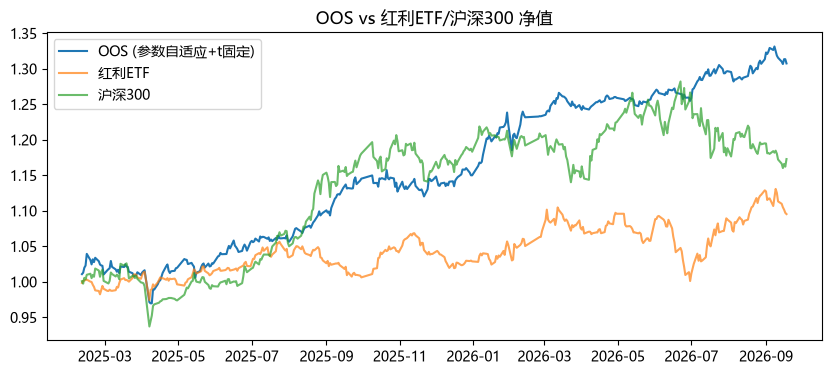

In [56]:
plot_oos_vs_bench(topk_res[0]['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

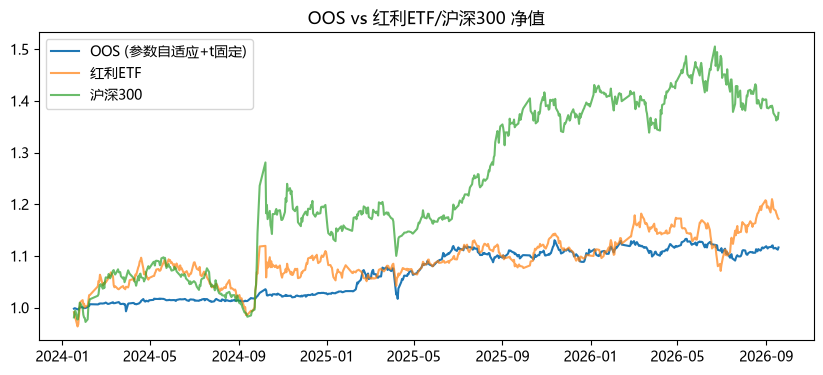

In [70]:
plot_oos_vs_bench(topk_res[0]['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

In [71]:
topk_pops = Population([res['mpt'] for res in topk_res])

In [58]:
topk_pops.plot_cumulative_returns()

In [72]:
topk_pops.plot_cumulative_returns()

In [12]:
topk_pops.plot_drawdowns()

In [66]:
topk_pops.plot_returns_distribution()

In [73]:
topk_pops.summary()

,top-0,top-1,top-2,top-3,top-4,top-5,top-6,top-7,top-8,top-9
Mean,0.018%,0.055%,0.027%,0.030%,0.046%,0.041%,0.066%,0.022%,0.026%,0.011%
Annualized Mean,4.45%,13.89%,6.84%,7.59%,11.55%,10.28%,16.69%,5.64%,6.46%,2.84%
Variance,0.000013,0.000041,0.000034,0.000033,0.000066,0.000018,0.000047,0.000012,0.000015,0.000051
Annualized Variance,0.33%,1.04%,0.85%,0.84%,1.68%,0.46%,1.20%,0.31%,0.39%,1.29%
Semi-Variance,0.000008,0.000023,0.000018,0.000018,0.000035,0.000009,0.000024,0.000007,0.000008,0.000029
Annualized Semi-Variance,0.20%,0.58%,0.46%,0.45%,0.88%,0.22%,0.60%,0.19%,0.21%,0.72%
Standard Deviation,0.36%,0.64%,0.58%,0.58%,0.82%,0.43%,0.69%,0.35%,0.39%,0.72%
Annualized Standard Deviation,5.77%,10.20%,9.24%,9.14%,12.94%,6.81%,10.93%,5.60%,6.21%,11.38%
Semi-Deviation,0.28%,0.48%,0.43%,0.42%,0.59%,0.30%,0.49%,0.27%,0.29%,0.53%
Annualized Semi-Deviation,4.47%,7.59%,6.81%,6.71%,9.40%,4.70%,7.74%,4.35%,4.54%,8.48%
